# Tarea 2: Mapa de Calor de Correlaciones y Clasificadores (Wine Dataset)
**Alumno:** Alacoria Cueto Emanuel

## Objetivos
1. Construir un **mapa de calor de correlaciones** sobre el dataset de vinos de `scikit-learn`.
2. Identificar la **tercera característica más representativa** según su correlación con la clase.
3. Graficar los **pares** de esa característica contra `Alcohol` y `Flavonoides`.
4. Evaluar **k-NN, Árbol de Decisión y Naive Bayes** para determinar cuál ofrece la **representación gráfica de clasificación más clara** (fronteras de decisión).

*Filosofía del taller (Teorema del "No Free Lunch"): ningún algoritmo es perfecto para todos los problemas; comparamos a los tres competidores en igualdad de condiciones.*

---
## **Paso 1: Carga del Dataset y Traducción de Columnas**

Utilizamos el dataset *Wine* incluido en `scikit-learn`. El objetivo es predecir de qué **cultivo (Clase 0, 1 o 2)** proviene un vino a partir de 13 mediciones químicas. Las columnas se traducen al español para facilitar la interpretación de los resultados.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_wine

datos_vino = load_wine()
X = pd.DataFrame(datos_vino.data, columns=datos_vino.feature_names)
y = pd.Series(datos_vino.target, name='Clase_de_Vino')

mapeo_columnas = {
    'alcohol': 'Alcohol',
    'malic_acid': 'Acido_Malico',
    'ash': 'Ceniza',
    'alcalinity_of_ash': 'Alcalinidad_Ceniza',
    'magnesium': 'Magnesio',
    'total_phenols': 'Fenoles_Totales',
    'flavanoids': 'Flavonoides',
    'nonflavanoid_phenols': 'Fenoles_No_Flavonoides',
    'proanthocyanins': 'Proantocianidinas',
    'color_intensity': 'Intensidad_Color',
    'hue': 'Matiz',
    'od280/od315_of_diluted_wines': 'OD280_OD315',
    'proline': 'Prolina'
}
X.rename(columns=mapeo_columnas, inplace=True)

print('Dimensiones:', X.shape)
print('Distribución de clases:', dict(zip(*np.unique(y, return_counts=True))))
print()
print(X.head().round(2).to_string())

Dimensiones: (178, 13)
Distribución de clases: {np.int64(0): np.int64(59), np.int64(1): np.int64(71), np.int64(2): np.int64(48)}

   Alcohol  Acido_Malico  Ceniza  Alcalinidad_Ceniza  Magnesio  Fenoles_Totales  Flavonoides  Fenoles_No_Flavonoides  Proantocianidinas  Intensidad_Color  Matiz  OD280_OD315  Prolina
0    14.23          1.71    2.43                15.6     127.0             2.80         3.06                    0.28               2.29              5.64   1.04         3.92   1065.0
1    13.20          1.78    2.14                11.2     100.0             2.65         2.76                    0.26               1.28              4.38   1.05         3.40   1050.0
2    13.16          2.36    2.67                18.6     101.0             2.80         3.24                    0.30               2.81              5.68   1.03         3.17   1185.0
3    14.37          1.95    2.50                16.8     113.0             3.85         3.49                    0.24               2.18   

---
## **Paso 2: Mapa de Calor de Correlaciones**

Se calcula la matriz de correlación (Pearson) entre las 13 características y la clase. 

**Criterio de representatividad:** una característica es más representativa para la clasificación cuando su **correlación con la clase** es más fuerte en valor absoluto (|r|). Esto se complementa con la correlación entre variables para detectar redundancia (variables altamente correlacionadas entre sí aportan información repetida).

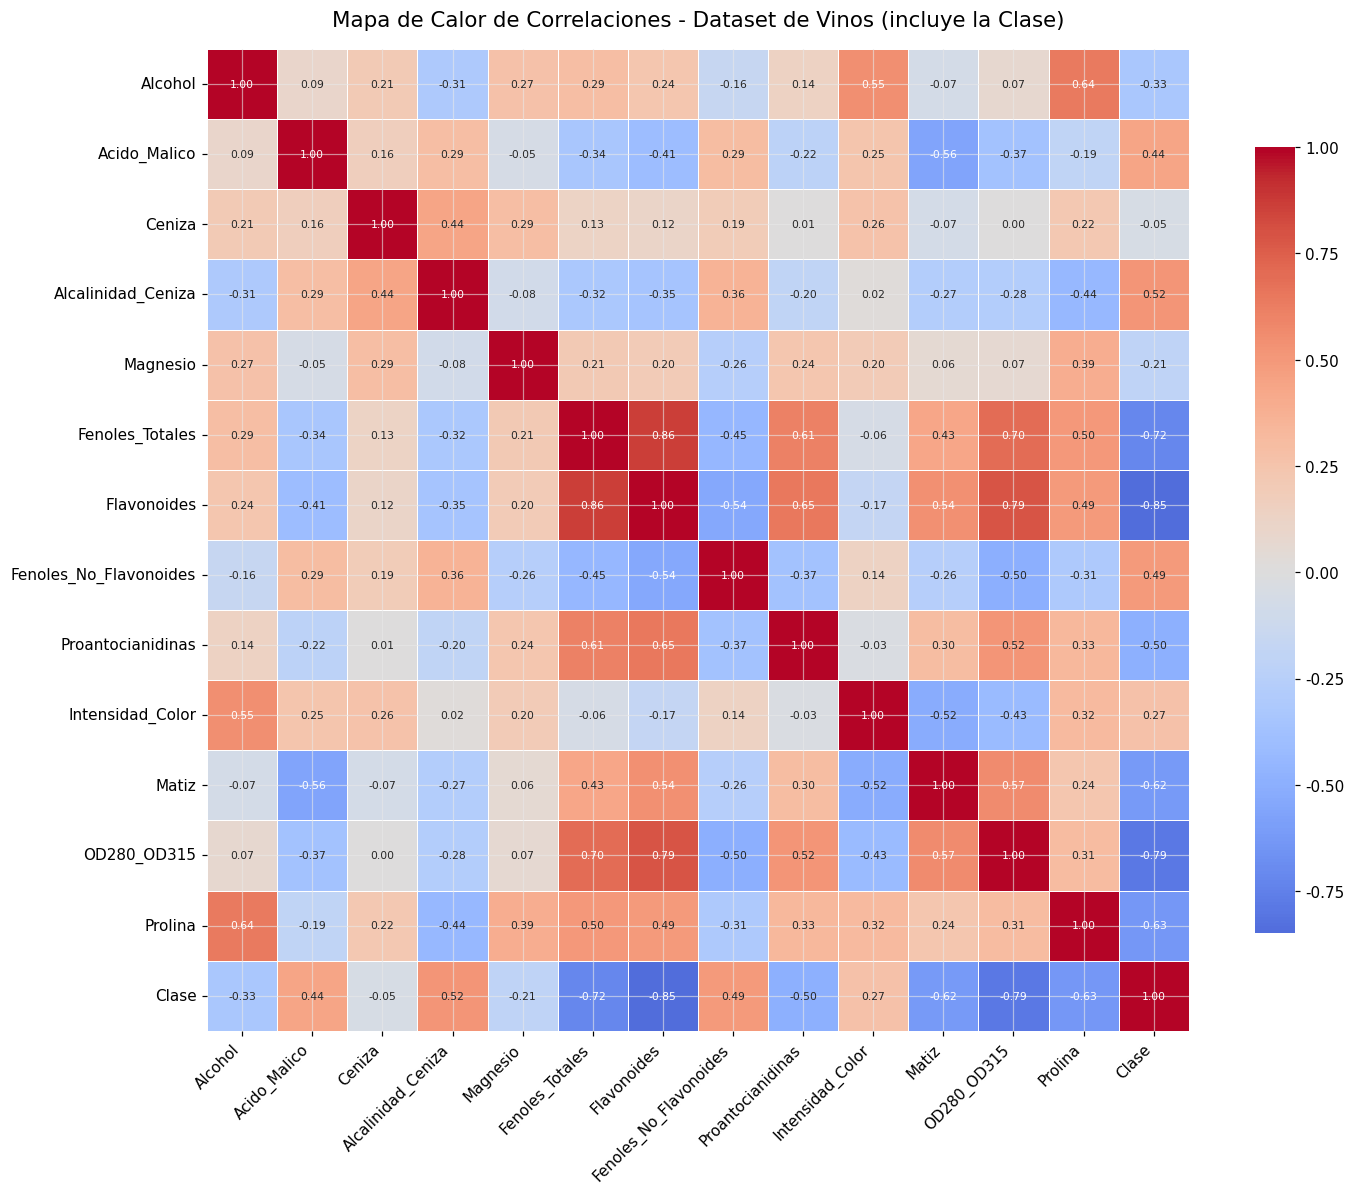

In [ ]:
# Matriz de correlación: características + clase
df_corr = X.copy()
df_corr['Clase'] = y
matriz_corr = df_corr.corr(numeric_only=True)

plt.figure(figsize=(14, 11))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8},
            annot_kws={'size': 7})
plt.title('Mapa de Calor de Correlaciones - Dataset de Vinos (incluye la Clase)', fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Lectura del mapa de calor:**
- Existe un **grupo de fenoles altamente correlacionados entre sí** (Flavonoides, Fenoles_Totales, OD280_OD315, Proantocianidinas, Matiz): miden compuestos químicos relacionados, por lo que se mueven juntos.
- La última fila/columna (`Clase`) muestra qué variables separan mejor los cultivos.

Ahora ordenamos las características por |correlación con la clase| para identificar el **podio de las 3 más representativas**:

In [ ]:
# Correlación de cada característica con la clase y ranking
corr_clase = matriz_corr['Clase'].drop('Clase')
ranking = corr_clase.abs().sort_values(ascending=False)

print('RANKING de características por |correlación con la Clase|:')
print('-' * 55)
for i, (feat, _) in enumerate(ranking.items(), 1):
    print(f'{i}. {feat:22s}  r = {corr_clase[feat]:+.3f}')
print('-' * 55)

top3 = list(ranking.index[:3])
print()
print('Top 3 más representativas:', top3)
print(f'>> TERCERA característica más representativa: {top3[2]} (r = {corr_clase[top3[2]]:+.3f})')

RANKING de características por |correlación con la Clase|:
-------------------------------------------------------
1. Flavonoides             r = -0.847
2. OD280_OD315             r = -0.788
3. Fenoles_Totales         r = -0.719
4. Prolina                 r = -0.634
5. Matiz                   r = -0.617
6. Alcalinidad_Ceniza      r = +0.518
7. Proantocianidinas       r = -0.499
8. Fenoles_No_Flavonoides  r = +0.489
9. Acido_Malico            r = +0.438
10. Alcohol                 r = -0.328
11. Intensidad_Color        r = +0.266
12. Magnesio                r = -0.209
13. Ceniza                  r = -0.050
-------------------------------------------------------

Top 3 más representativas: ['Flavonoides', 'OD280_OD315', 'Fenoles_Totales']
>> TERCERA característica más representativa: Fenoles_Totales (r = -0.719)


---
## **Paso 3: Gráficas de Pares (Pair Plots) de la Tercera Característica**

La tercera característica más representativa es **Fenoles_Totales** (r = −0.72 con la clase). Se grafican los pares:

- **Fenoles_Totales vs Alcohol**
- **Fenoles_Totales vs Flavonoides** (la más representativa, r = −0.85)

Cada punto es un vino, coloreado por cultivo. Las nubes de puntos separadas indican que el par de variables es buen candidato para visualizar las fronteras de clasificación.

Correlación Fenoles_Totales vs Alcohol   : 0.289
Correlación Fenoles_Totales vs Flavonoides: 0.865


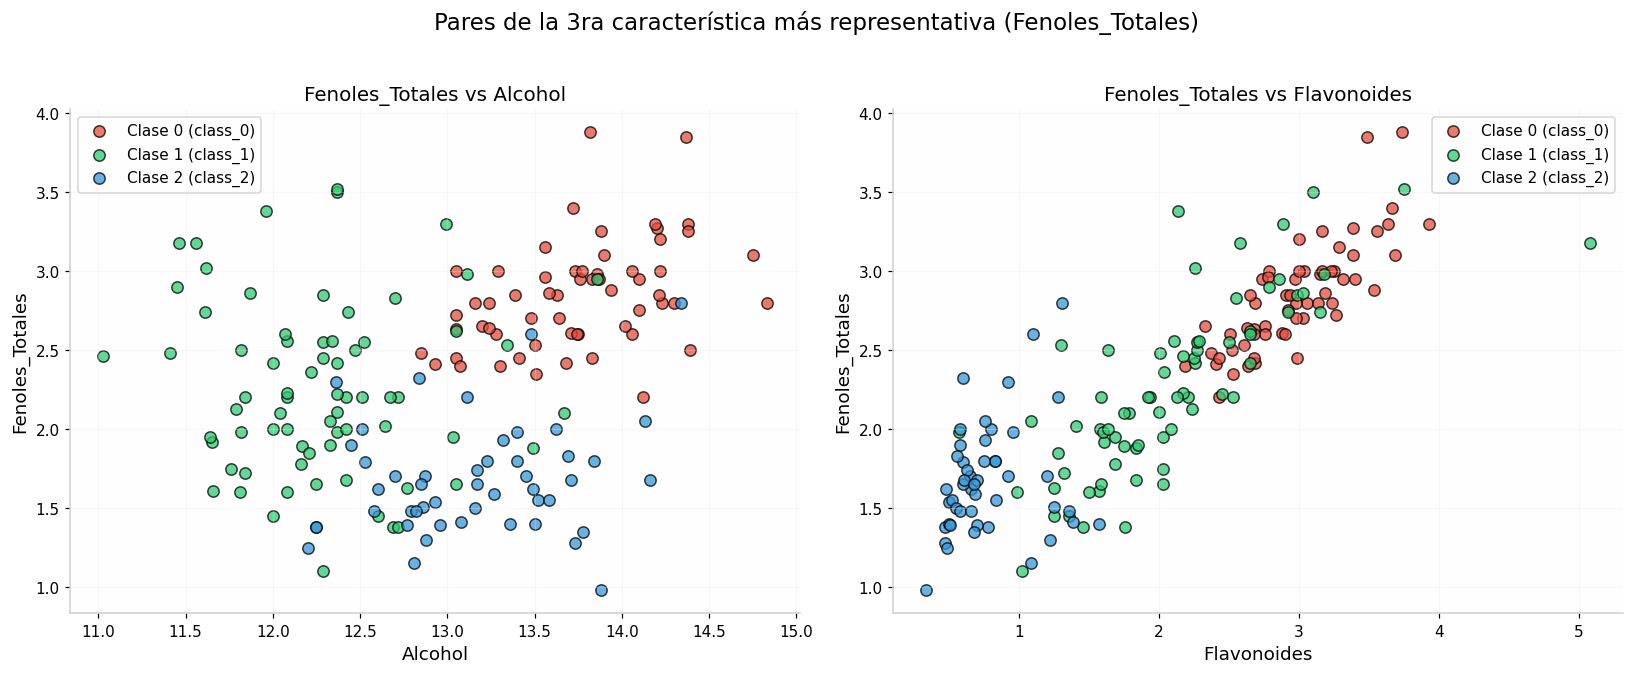

In [ ]:
tercera = 'Fenoles_Totales'
pares = [('Alcohol', tercera), ('Flavonoides', tercera)]
colores = {0: '#e74c3c', 1: '#2ecc71', 2: '#3498db'}
nombres_clases = dict(enumerate(datos_vino.target_names))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (var_x, var_y) in zip(axes, pares):
    for clase in [0, 1, 2]:
        mask = (y == clase)
        ax.scatter(X.loc[mask, var_x], X.loc[mask, var_y],
                   c=colores[clase], label=f'Clase {clase} ({nombres_clases[clase]})',
                   edgecolor='k', alpha=0.75, s=55)
    ax.set_xlabel(var_x, fontsize=12)
    ax.set_ylabel(var_y, fontsize=12)
    ax.set_title(f'{var_y} vs {var_x}', fontsize=13)
    ax.legend()
    ax.grid(alpha=0.3)
plt.suptitle('Pares de la 3ra característica más representativa (Fenoles_Totales)', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

# Correlaciones entre las variables de los pares
print('Correlación Fenoles_Totales vs Alcohol   :', round(X['Fenoles_Totales'].corr(X['Alcohol']), 3))
print('Correlación Fenoles_Totales vs Flavonoides:', round(X['Fenoles_Totales'].corr(X['Flavonoides']), 3))

---
## **Paso 4: Evaluación de k-NN, Árbol de Decisión y Naive Bayes**

Se entrenan los tres clasificadores sobre **cada par de variables** (solo 2 dimensiones, para poder graficar las fronteras después):

1. **k-NN** (`n_neighbors=5`): requiere escalamiento porque decide por distancias.
2. **Árbol de Decisión** (`max_depth=4`): usa reglas If-Then, no requiere escalamiento (pero se aplica igualmente para comparar en el mismo espacio).
3. **Naive Bayes** (Gaussiano): decide por probabilidad; el escalamiento no cambia sus campanas de distribución.

División: 70% entrenamiento / 30% prueba, estratificada, `random_state=42`.

             Par de variables            Modelo  Accuracy
    Alcohol + Fenoles_Totales              k-NN     0.815
    Alcohol + Fenoles_Totales Árbol de Decisión     0.778
    Alcohol + Fenoles_Totales       Naive Bayes     0.778
Flavonoides + Fenoles_Totales              k-NN     0.778
Flavonoides + Fenoles_Totales Árbol de Decisión     0.796
Flavonoides + Fenoles_Totales       Naive Bayes     0.889


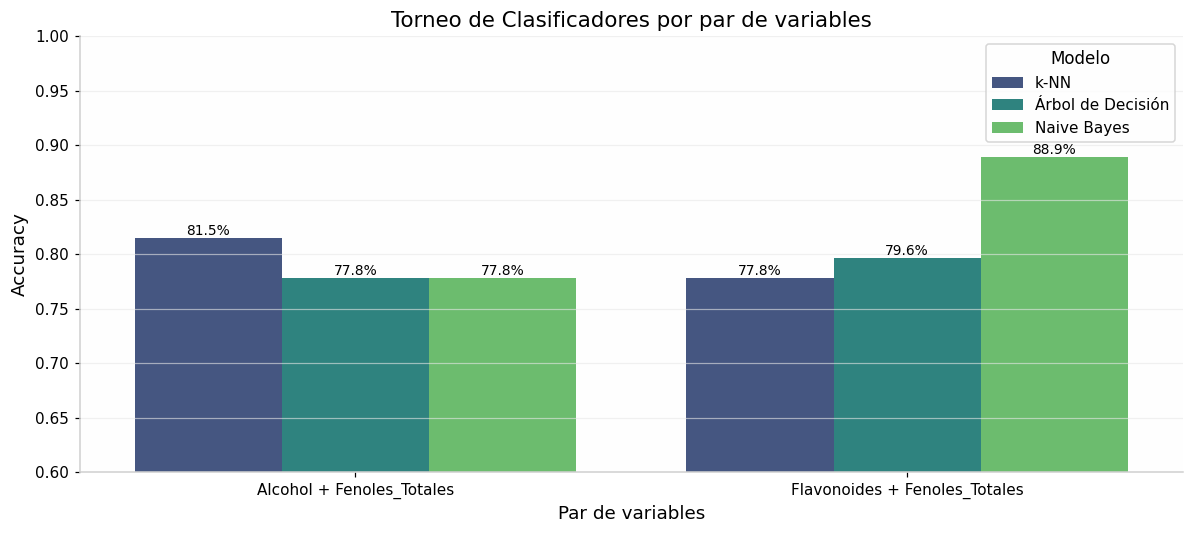

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

pares = {'Alcohol + Fenoles_Totales': ['Alcohol', 'Fenoles_Totales'],
         'Flavonoides + Fenoles_Totales': ['Flavonoides', 'Fenoles_Totales']}
modelos = {'k-NN': lambda: KNeighborsClassifier(5),
           'Árbol de Decisión': lambda: DecisionTreeClassifier(max_depth=4, random_state=42),
           'Naive Bayes': GaussianNB}

filas = []
for nombre_par, cols in pares.items():
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_train[cols])
    Xte = scaler.transform(X_test[cols])
    for nombre_mod, mk in modelos.items():
        m = mk().fit(Xtr, y_train)
        filas.append({'Par de variables': nombre_par,
                      'Modelo': nombre_mod,
                      'Accuracy': round(accuracy_score(y_test, m.predict(Xte)), 3)})

df_resultados = pd.DataFrame(filas)
print(df_resultados.to_string(index=False))

plt.figure(figsize=(11, 5))
ax = sns.barplot(data=df_resultados, x='Par de variables', y='Accuracy',
                 hue='Modelo', palette='viridis')
for p in ax.patches:
    ax.annotate(f'{p.get_height()*100:.1f}%', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.title('Torneo de Clasificadores por par de variables')
plt.ylim(0.6, 1.0)
plt.tight_layout()
plt.show()

---
## **Paso 5: Representación Gráfica de las Fronteras de Decisión**

Cada modelo "corta" el plano de forma distinta. Al comparar las fronteras visualmente se determina cuál ofrece la **clasificación más clara**:

- **k-NN** → fronteras curvas e irregulares que rodean a los vecinos.
- **Árbol de Decisión** → fronteras rectangulares (cortes horizontales/verticales).
- **Naive Bayes** → zonas suaves y amplias dictadas por probabilidad.

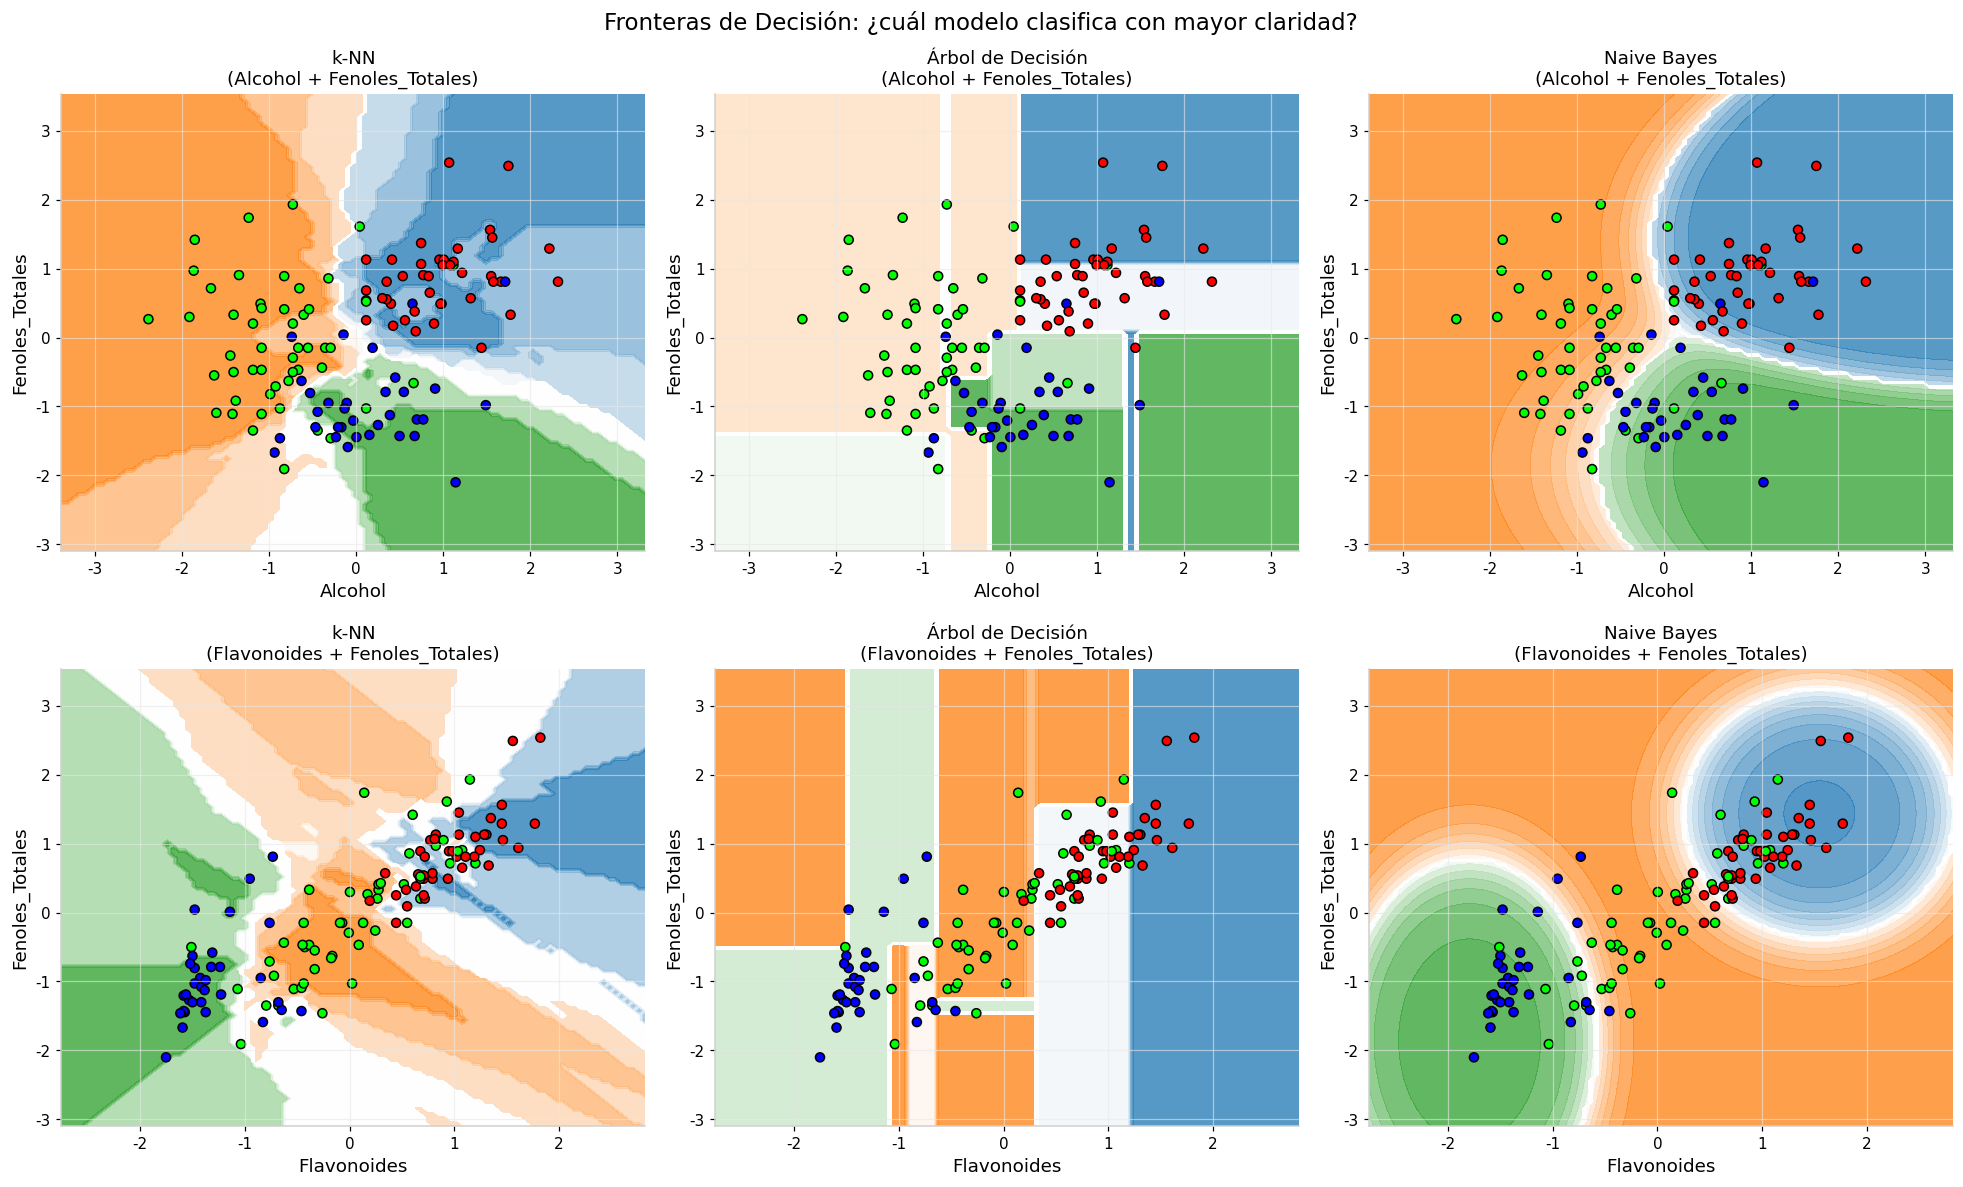

In [ ]:
from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap

cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold  = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for fila, (nombre_par, cols) in enumerate(pares.items()):
    s = StandardScaler()
    X2 = s.fit_transform(X_train[cols])
    for col_ax, (nombre_mod, mk) in zip(axes[fila], modelos.items()):
        m = mk().fit(X2, y_train)
        DecisionBoundaryDisplay.from_estimator(m, X2, cmap=cmap_light, ax=col_ax, alpha=0.8)
        col_ax.scatter(X2[:, 0], X2[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=35)
        col_ax.set_title(f'{nombre_mod}\n({nombre_par})', fontsize=12)
        col_ax.set_xlabel(cols[0]); col_ax.set_ylabel(cols[1])
plt.suptitle('Fronteras de Decisión: ¿cuál modelo clasifica con mayor claridad?', fontsize=15)
plt.tight_layout()
plt.show()

---
## **Conclusión: ¿Cuál modelo ofrece la representación gráfica más clara?**

**Ganador: Naive Bayes sobre el par Flavonoides + Fenoles_Totales (88.9% de accuracy).**

1. **Naive Bayes** genera fronteras suaves, contiguas y amplias, dictadas por campanas de probabilidad. En el par Flavonoides + Fenoles_Totales separa limpiamente la Clase 2 (baja en ambos fenoles) de las demás y logra la mayor exactitud del torneo (**88.9%**). Visualmente es la representación más clara y generalizable.
2. **k-NN** produce fronteras curvas pero irregulares y fragmentadas que "rodean" grupos de puntos; es expresivo, pero sobreajusta localmente (77.8% en el par de fenoles, aunque gana en el par con Alcohol con 81.5%).
3. **Árbol de Decisión** solo puede hacer cortes rectos horizontales/verticales (reglas If-Then). Es el más interpretable —se pueden leer las reglas en voz alta—, pero sus rectángulos son una aproximación tosca a la frontera real (79.6%).

**Nota sobre el par con Alcohol:** las tres clases se solapan considerablemente porque Alcohol tiene solo r = −0.33 con la clase; por eso ningún modelo supera el 81.5% en ese par.

**Decisión final:**
- Para **visualización clara del fenómeno químico** (qué cultivos se separan y por qué zona del espectro de fenoles): **Naive Bayes con (Flavonoides, Fenoles_Totales)**.
- Para **explicabilidad regla-por-regla** ante un químico o auditor: **Árbol de Decisión**.

Esto ilustra el teorema del *No Free Lunch*: no hay un algoritmo universalmente superior; la elección depende del objetivo (exactitud, claridad visual o interpretabilidad).